# CUB-200-2011 manifest and exploratory data analysis

This notebook builds a dataset manifest OF CUB-200-2011 text files, enriches it with properties read from the JPEG files, validates the joins, exports analysis-ready tables, and performs basic EDA.

### Outputs

The `manifest_outputs/` directory will contain:

* `cub_200_2011_image_manifest.csv` and `.parquet`: one row per image, official class/split/bounding-box metadata, image properties, part summaries, and all 312 binary image attributes.
* `cub_200_2011_image_attribute_annotations.parque`: the complete long-form image-attribute table, including certainty and annotation time.
* `cub_200_2011_class_attribute_manifest.csv` and `.parquet`: all class-level continuous attribute percentages.
* `cub_200_2011_part_locations.parquet` and `cub_200_2011_part_click_annotations.parquet`: official consensus and MTurk part annotations.
* lookup tables, source-file inventory, validation results, and a JSON summary.

### Important interpretation notes

* Although one line of the supplied README says 322 attributes, the supplied lookup and annotation matrices contain **312** attributes. The notebook derives this value from the files and validates it.
* JPEG does not store the original uncompressed bitmap or a reliable encoder “quality” setting. `estimated_uncompressed_bytes`, `estimated_compression_ratio`, and `encoded_bits_per_pixel` are transparent proxies based on pixel dimensions, mode/bands, and file size—not recovered JPEG settings.
* The notebook uses every dataset-provided `.txt` annotation table, including the MTurk part clicks. In this extracted copy, `attributes.txt` is one directory above the dataset root; path discovery handles both the documented and observed locations.
* The supplied `image_attribute_labels.txt` has 606 rows with an undocumented sixth field: attributes 10–312 for image IDs 2275 and 9364 contain an extra `0` before annotation time. The parser preserves it as nullable `source_extra_field` rather than dropping or shifting those rows.


In [12]:
from pathlib import Path
import json
import re
import time

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.style.use("seaborn-v0_8-whitegrid")

NOTEBOOK_DIR = Path.cwd().resolve()

DATASET_ROOT = Path(r"E:\Datasets\CUB_200\CUB_200_2011")

OUTPUT_DIR = Path(r"C:\Users\Joe\Desktop\ESP Classifier\esp32_Classifier\Notebooks")

documented_attribute_path = DATASET_ROOT / "attributes" / "attributes.txt"
observed_attribute_path = DATASET_ROOT.parent / "attributes.txt"
ATTRIBUTE_NAMES_PATH = (
    documented_attribute_path if documented_attribute_path.exists() else observed_attribute_path
)

print(f"Notebook directory: {NOTEBOOK_DIR}")
print(f"Dataset root:       {DATASET_ROOT}")
print(f"Output directory:   {OUTPUT_DIR}")
print(f"Attribute lookup:   {ATTRIBUTE_NAMES_PATH}")


Notebook directory: C:\Users\Joe\Desktop\ESP Classifier\esp32_Classifier\Notebooks
Dataset root:       E:\Datasets\CUB_200\CUB_200_2011
Output directory:   C:\Users\Joe\Desktop\ESP Classifier\esp32_Classifier\Notebooks
Attribute lookup:   E:\Datasets\CUB_200\attributes.txt


## Parsing and image-inspection helpers

Lookup files are read with `split(maxsplit=1)` so names such as “left eye” remain intact. Numeric annotation tables use whitespace-delimited parsing and explicit column names/dtypes.

In [14]:
def read_lookup(path: Path, id_column: str, name_column: str) -> pd.DataFrame:
    records = []
    with path.open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            fields = line.strip().split(maxsplit=1)
            if len(fields) != 2:
                raise ValueError(f"Malformed lookup row at {path}:{line_number}: {line!r}")
            records.append((int(fields[0]), fields[1]))
    return pd.DataFrame(records, columns=[id_column, name_column])


def read_numeric_table(path: Path, names, dtype=None) -> pd.DataFrame:
    return pd.read_csv(path, sep=r"\s+", header=None, names=names, dtype=dtype)


def read_image_attribute_table(path: Path) -> pd.DataFrame:
    # Most rows have the documented 5 fields; 606 supplied rows have an extra zero
    # before time. Reading 6 columns first prevents either data loss or column shifting.
    columns = [
        "image_id", "attribute_id", "is_present", "certainty_id",
        "source_extra_field", "annotation_time_seconds",
    ]
    frame = pd.read_csv(
        path, sep=r"\s+", header=None, names=columns,
        dtype={
            "image_id": "int32", "attribute_id": "int16", "is_present": "int8",
            "certainty_id": "int8", "source_extra_field": "float32",
            "annotation_time_seconds": "float32",
        },
    )
    documented_rows = frame["annotation_time_seconds"].isna()
    frame.loc[documented_rows, "annotation_time_seconds"] = frame.loc[documented_rows, "source_extra_field"]
    frame.loc[documented_rows, "source_extra_field"] = np.nan
    return frame


def safe_attribute_column(name: str, prefix: str) -> str:
    normalized = name.replace("::", "__")
    normalized = re.sub(r"[^0-9A-Za-z]+", "_", normalized).strip("_").lower()
    return f"{prefix}{normalized}"


def inspect_image(image_id: int, absolute_path: Path) -> dict:
    record = {"image_id": image_id, "file_exists": absolute_path.is_file(), "scan_error": None}
    if not record["file_exists"]:
        record["scan_error"] = "file not found"
        return record
    try:
        file_bytes = absolute_path.stat().st_size
        with Image.open(absolute_path) as image:
            width, height = image.size
            bands = image.getbands()
            image_format = image.format
            image_mode = image.mode
        pixels = width * height
        channel_count = len(bands)
        # CUB JPEGs use 8-bit bands. This is a decoded-array-size estimate, not JPEG quality.
        estimated_uncompressed_bytes = pixels * channel_count
        record.update({
            "image_format": image_format,
            "image_mode": image_mode,
            "channel_count": channel_count,
            "width_px": width,
            "height_px": height,
            "pixel_count": pixels,
            "megapixels": pixels / 1_000_000,
            "aspect_ratio": width / height,
            "orientation": "landscape" if width > height else ("portrait" if height > width else "square"),
            "file_bytes": file_bytes,
            "file_size_kib": file_bytes / 1024,
            "estimated_uncompressed_bytes": estimated_uncompressed_bytes,
            "estimated_compression_ratio": estimated_uncompressed_bytes / file_bytes,
            "encoded_bits_per_pixel": (8 * file_bytes) / pixels,
        })
    except Exception as exc:  # preserve a manifest row even for a corrupt image
        record["scan_error"] = f"{type(exc).__name__}: {exc}"
    return record


def write_parquet(frame: pd.DataFrame, path: Path) -> None:
    try:
        frame.to_parquet(path, index=False, compression="snappy")
    except ImportError as exc:
        raise ImportError("Parquet export requires pyarrow or fastparquet. Install pyarrow and rerun.") from exc


## 1. Load official image, class, split, and bounding-box tables

In [16]:
source_paths = {
    "images": DATASET_ROOT / "images.txt",
    "image_class_labels": DATASET_ROOT / "image_class_labels.txt",
    "classes": DATASET_ROOT / "classes.txt",
    "train_test_split": DATASET_ROOT / "train_test_split.txt",
    "bounding_boxes": DATASET_ROOT / "bounding_boxes.txt",
    "attribute_names": ATTRIBUTE_NAMES_PATH,
    "certainties": DATASET_ROOT / "attributes" / "certainties.txt",
    "image_attribute_labels": DATASET_ROOT / "attributes" / "image_attribute_labels.txt",
    "class_attribute_labels_continuous": DATASET_ROOT / "attributes" / "class_attribute_labels_continuous.txt",
    "parts": DATASET_ROOT / "parts" / "parts.txt",
    "part_locs": DATASET_ROOT / "parts" / "part_locs.txt",
    "part_click_locs": DATASET_ROOT / "parts" / "part_click_locs.txt",
}
missing_sources = [str(path) for path in source_paths.values() if not path.is_file()]
assert not missing_sources, f"Missing required source files: {missing_sources}"

images = read_numeric_table(source_paths["images"], ["image_id", "relative_path"])
image_classes = read_numeric_table(
    source_paths["image_class_labels"], ["image_id", "class_id"], dtype={"image_id": "int32", "class_id": "int16"}
)
classes = read_lookup(source_paths["classes"], "class_id", "class_name")
classes["class_name_friendly"] = classes["class_name"].str.replace(r"^\d+\.", "", regex=True).str.replace("_", " ")
split = read_numeric_table(
    source_paths["train_test_split"], ["image_id", "is_training_image"], dtype={"image_id": "int32", "is_training_image": "int8"}
)
boxes = read_numeric_table(
    source_paths["bounding_boxes"], ["image_id", "bbox_x", "bbox_y", "bbox_width", "bbox_height"]
)

manifest = (
    images.merge(image_classes, on="image_id", validate="one_to_one")
    .merge(classes, on="class_id", validate="many_to_one")
    .merge(split, on="image_id", validate="one_to_one")
    .merge(boxes, on="image_id", validate="one_to_one")
)
manifest["split"] = manifest["is_training_image"].map({1: "train", 0: "test"})
manifest["image_path"] = manifest["relative_path"].map(lambda value: str((DATASET_ROOT / "images" / value).resolve()))

assert manifest["image_id"].is_unique
assert set(manifest["split"]) == {"train", "test"}
assert (manifest["class_id"].nunique(), len(manifest)) == (200, 11_788)
display(manifest.head())
print(f"Loaded {len(manifest):,} images across {manifest['class_id'].nunique()} classes.")


,image_id,relative_path,class_id,class_name,class_name_friendly,is_training_image,bbox_x,bbox_y,bbox_width,bbox_height,split,image_path
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Black footed Albatross,0,60.0,27.0,325.0,304.0,test,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Black footed Albatross,1,139.0,30.0,153.0,264.0,train,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Black footed Albatross,0,14.0,112.0,388.0,186.0,test,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Black footed Albatross,1,112.0,90.0,255.0,242.0,train,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Black footed Albatross,1,70.0,50.0,134.0,303.0,train,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...


Loaded 11,788 images across 200 classes.


## 2. Inspect each JPEG

This reads JPEG headers (not full decoded pixel arrays), so memory use remains low. Compression metrics are estimates described at the top of the notebook.

In [18]:
started = time.perf_counter()
image_records = []
for row_number, row in enumerate(manifest[["image_id", "image_path"]].itertuples(index=False), start=1):
    image_records.append(inspect_image(row.image_id, Path(row.image_path)))
    if row_number % 2_000 == 0:
        print(f"Inspected {row_number:,}/{len(manifest):,} images")

image_properties = pd.DataFrame(image_records)
manifest = manifest.merge(image_properties, on="image_id", validate="one_to_one")
print(f"Image inspection completed in {time.perf_counter() - started:.1f} seconds.")
print(manifest["scan_error"].value_counts(dropna=False))
display(manifest[["width_px", "height_px", "file_size_kib", "estimated_compression_ratio", "encoded_bits_per_pixel"]].describe().T)


Inspected 2,000/11,788 images
Inspected 4,000/11,788 images
Inspected 6,000/11,788 images
Inspected 8,000/11,788 images
Inspected 10,000/11,788 images
Image inspection completed in 209.5 seconds.
scan_error
None    11788
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
width_px,11788.0,467.886834,63.930494,121.000000,495.000000,500.000000,500.000000,500.000000
height_px,11788.0,386.029946,70.890307,120.000000,333.000000,375.000000,434.000000,500.000000
file_size_kib,11788.0,95.324241,42.323225,2.559570,68.138428,91.673828,118.681885,358.228516
estimated_compression_ratio,11788.0,6.919600,4.827953,1.305970,4.541170,5.755934,7.464088,85.338645
encoded_bits_per_pixel,11788.0,4.335052,1.775891,0.281232,3.210519,4.169066,5.282337,18.377143


## 3. Load part locations and MTurk part clicks

Both part tables supplied by the dataset are retained in long form. Per-image summaries are also joined into the image manifest.

In [20]:
parts = read_lookup(source_paths["parts"], "part_id", "part_name")
part_locations = read_numeric_table(
    source_paths["part_locs"],
    ["image_id", "part_id", "part_x", "part_y", "part_visible"],
    dtype={"image_id": "int32", "part_id": "int8", "part_visible": "int8"},
).merge(parts, on="part_id", validate="many_to_one")

part_clicks = read_numeric_table(
    source_paths["part_click_locs"],
    ["image_id", "part_id", "click_x", "click_y", "click_visible", "click_time_seconds"],
    dtype={"image_id": "int32", "part_id": "int8", "click_visible": "int8", "click_time_seconds": "float32"},
).merge(parts, on="part_id", validate="many_to_one")

assert len(parts) == 15
assert part_locations.groupby("image_id").size().eq(len(parts)).all()

part_summary = part_locations.groupby("image_id", as_index=False).agg(
    visible_part_count=("part_visible", "sum")
)
click_summary = part_clicks.groupby("image_id", as_index=False).agg(
    mturk_part_click_count=("part_id", "size"),
    mturk_visible_part_click_count=("click_visible", "sum"),
    mturk_mean_click_time_seconds=("click_time_seconds", "mean"),
)
manifest = (
    manifest.merge(part_summary, on="image_id", validate="one_to_one")
    .merge(click_summary, on="image_id", validate="one_to_one")
)
display(part_locations.head())
print(f"Part locations: {len(part_locations):,}; MTurk part clicks: {len(part_clicks):,}")


,image_id,part_id,part_x,part_y,part_visible,part_name
0,1,1,0.0,0.0,0,back
1,1,2,312.0,182.0,1,beak
2,1,3,0.0,0.0,0,belly
3,1,4,0.0,0.0,0,breast
4,1,5,186.0,45.0,1,crown


Part locations: 176,820; MTurk part clicks: 794,258


## 4. Load all image-level and class-level attributes

The complete 3.68-million-row image-attribute table is parsed with compact dtypes. Its binary labels are pivoted to make the one-row-per-image manifest; certainty, time, and the 606-row undocumented source field stay in the lossless long-form export.

In [22]:
attributes = read_lookup(source_paths["attribute_names"], "attribute_id", "attribute_name")
certainties = read_lookup(source_paths["certainties"], "certainty_id", "certainty_name")

attribute_annotations = read_image_attribute_table(source_paths["image_attribute_labels"])

number_of_attributes = len(attributes)
expected_annotations = len(manifest) * number_of_attributes
assert number_of_attributes == 312, f"Expected the supplied 312 attributes, found {number_of_attributes}"
assert len(attribute_annotations) == expected_annotations
assert not attribute_annotations.duplicated(["image_id", "attribute_id"]).any()
assert attribute_annotations.groupby("image_id").size().eq(number_of_attributes).all()
assert set(attribute_annotations["is_present"].unique()).issubset({0, 1})
assert attribute_annotations["annotation_time_seconds"].notna().all()
assert attribute_annotations["source_extra_field"].notna().sum() == 606
assert set(attribute_annotations.loc[attribute_annotations["source_extra_field"].notna(), "source_extra_field"]) == {0.0}

attribute_columns = attributes.copy()
attribute_columns["manifest_column"] = attribute_columns["attribute_name"].map(
    lambda name: safe_attribute_column(name, "attr_present__")
)
assert attribute_columns["manifest_column"].is_unique

present_wide = attribute_annotations.pivot(
    index="image_id", columns="attribute_id", values="is_present"
)
present_wide.columns = attribute_columns.set_index("attribute_id").loc[present_wide.columns, "manifest_column"]
present_wide = present_wide.reset_index()
manifest = manifest.merge(present_wide, on="image_id", validate="one_to_one")

# Preserve descriptive names in the normalized export.
attribute_annotations = (
    attribute_annotations.merge(attributes, on="attribute_id", validate="many_to_one")
    .merge(certainties, on="certainty_id", validate="many_to_one")
)

class_attribute_values = np.loadtxt(source_paths["class_attribute_labels_continuous"], dtype=np.float32)
assert class_attribute_values.shape == (len(classes), number_of_attributes)
class_attribute_columns = attributes["attribute_name"].map(
    lambda name: safe_attribute_column(name, "attr_prevalence_pct__")
).tolist()
class_attribute_manifest = pd.concat(
    [classes.reset_index(drop=True), pd.DataFrame(class_attribute_values, columns=class_attribute_columns)],
    axis=1,
)

print(f"Attributes: {number_of_attributes}; image-attribute annotations: {len(attribute_annotations):,}")
print(f"Rows retaining the undocumented extra source field: {attribute_annotations['source_extra_field'].notna().sum():,}")
display(attribute_annotations.head())
display(class_attribute_manifest.iloc[:5, :10])


Attributes: 312; image-attribute annotations: 3,677,856
Rows retaining the undocumented extra source field: 606


,image_id,attribute_id,is_present,certainty_id,source_extra_field,annotation_time_seconds,attribute_name,certainty_name
0,1,1,0,3,NaN,27.708,has_bill_shape::curved_(up_or_down),probably
1,1,2,0,3,NaN,27.708,has_bill_shape::dagger,probably
2,1,3,0,3,NaN,27.708,has_bill_shape::hooked,probably
3,1,4,0,3,NaN,27.708,has_bill_shape::needle,probably
4,1,5,1,3,NaN,27.708,has_bill_shape::hooked_seabird,probably


,class_id,class_name,class_name_friendly,attr_prevalence_pct__has_bill_shape_curved_up_or_down,attr_prevalence_pct__has_bill_shape_dagger,attr_prevalence_pct__has_bill_shape_hooked,attr_prevalence_pct__has_bill_shape_needle,attr_prevalence_pct__has_bill_shape_hooked_seabird,attr_prevalence_pct__has_bill_shape_spatulate,attr_prevalence_pct__has_bill_shape_all_purpose
0,1,001.Black_footed_Albatross,Black footed Albatross,0.000000,2.919708,1.459854,0.000000,59.854015,26.277372,3.649635
1,2,002.Laysan_Albatross,Laysan Albatross,4.411765,4.411765,2.941176,1.470588,57.352940,27.205883,0.000000
2,3,003.Sooty_Albatross,Sooty Albatross,0.000000,3.973510,3.311258,0.000000,70.860924,14.569536,5.298013
3,4,004.Groove_billed_Ani,Groove billed Ani,0.000000,1.459854,10.218978,0.000000,0.000000,0.000000,8.759124
4,5,005.Crested_Auklet,Crested Auklet,0.000000,0.000000,3.225806,0.000000,1.075269,0.000000,0.000000


## 5. Derived manifest fields and validation

Bounding-box coverage is the box area divided by image area. A small coordinate tolerance is used for bounds checks because annotations may lie on an image edge.

In [24]:
manifest["bbox_right"] = manifest["bbox_x"] + manifest["bbox_width"]
manifest["bbox_bottom"] = manifest["bbox_y"] + manifest["bbox_height"]
manifest["bbox_area_fraction"] = (
    manifest["bbox_width"] * manifest["bbox_height"] / manifest["pixel_count"]
)
manifest["bbox_within_image"] = (
    manifest["bbox_x"].ge(0)
    & manifest["bbox_y"].ge(0)
    & manifest["bbox_right"].le(manifest["width_px"] + 1)
    & manifest["bbox_bottom"].le(manifest["height_px"] + 1)
)

attribute_manifest_columns = attribute_columns["manifest_column"].tolist()
manifest["present_attribute_count"] = manifest[attribute_manifest_columns].sum(axis=1)

validation = pd.DataFrame([
    ("image manifest has 11,788 rows", len(manifest) == 11_788, len(manifest)),
    ("image_id is unique", manifest["image_id"].is_unique, manifest["image_id"].nunique()),
    ("200 classes are represented", manifest["class_id"].nunique() == 200, manifest["class_id"].nunique()),
    ("all image files exist", bool(manifest["file_exists"].all()), int(manifest["file_exists"].sum())),
    ("all images scanned successfully", manifest["scan_error"].isna().all(), int(manifest["scan_error"].isna().sum())),
    ("all bounding boxes are within image tolerance", bool(manifest["bbox_within_image"].all()), int(manifest["bbox_within_image"].sum())),
    ("312 binary attribute columns were created", len(attribute_manifest_columns) == 312, len(attribute_manifest_columns)),
    ("each image has 15 part labels", len(part_locations) == len(manifest) * 15, len(part_locations)),
], columns=["check", "passed", "observed"])
display(validation)
if not validation["passed"].all():
    print("WARNING: At least one validation check failed; inspect the table before modeling.")


,check,passed,observed
0,"image manifest has 11,788 rows",True,11788
1,image_id is unique,True,11788
2,200 classes are represented,True,200
3,all image files exist,True,11788
4,all images scanned successfully,True,11788
5,all bounding boxes are within image tolerance,False,11780
6,312 binary attribute columns were created,True,312
7,each image has 15 part labels,True,176820


## 6. Export manifests and normalized annotation tables

CSV is provided for portability for the two manifest tables. Parquet is preferred for type preservation, speed, and the larger normalized tables.

In [30]:
# Put identifiers and frequently used fields first; retain every remaining column.
front_columns = [
    "image_id", "relative_path", "image_path", "class_id", "class_name", "class_name_friendly",
    "is_training_image", "split", "bbox_x", "bbox_y", "bbox_width", "bbox_height",
    "bbox_right", "bbox_bottom", "bbox_area_fraction", "bbox_within_image",
    "width_px", "height_px", "pixel_count", "megapixels", "aspect_ratio", "orientation",
    "image_format", "image_mode", "channel_count", "file_bytes", "file_size_kib",
    "estimated_uncompressed_bytes", "estimated_compression_ratio", "encoded_bits_per_pixel",
    "file_exists", "scan_error", "visible_part_count", "mturk_part_click_count",
    "mturk_visible_part_click_count", "mturk_mean_click_time_seconds", "present_attribute_count",
]
manifest = manifest[front_columns + [column for column in manifest.columns if column not in front_columns]]

manifest_csv = OUTPUT_DIR / "cub_200_2011_image_manifest.csv"
manifest.to_csv(manifest_csv, index=False)

class_attribute_manifest.to_csv(OUTPUT_DIR / "cub_200_2011_class_attribute_manifest.csv", index=False)


attribute_columns.to_csv(OUTPUT_DIR / "attribute_dictionary.csv", index=False)
parts.to_csv(OUTPUT_DIR / "part_dictionary.csv", index=False)
certainties.to_csv(OUTPUT_DIR / "certainty_dictionary.csv", index=False)
validation.to_csv(OUTPUT_DIR / "validation_results.csv", index=False)

source_inventory = pd.DataFrame([
    {
        "table": table,
        "source_path": str(path.resolve()),
        "size_bytes": path.stat().st_size,
        "line_count": sum(1 for _ in path.open("rb")),
    }
    for table, path in source_paths.items()
])
source_inventory.to_csv(OUTPUT_DIR / "source_file_inventory.csv", index=False)

summary = {
    "dataset": "CUB-200-2011",
    "dataset_root": str(DATASET_ROOT),
    "image_count": int(len(manifest)),
    "class_count": int(manifest["class_id"].nunique()),
    "attribute_count": int(number_of_attributes),
    "train_image_count": int((manifest["split"] == "train").sum()),
    "test_image_count": int((manifest["split"] == "test").sum()),
    "missing_image_count": int((~manifest["file_exists"]).sum()),
    "scan_error_count": int(manifest["scan_error"].notna().sum()),
    "total_jpeg_bytes": int(manifest["file_bytes"].sum()),
    "median_width_px": float(manifest["width_px"].median()),
    "median_height_px": float(manifest["height_px"].median()),
    "median_file_size_kib": float(manifest["file_size_kib"].median()),
    "median_estimated_compression_ratio": float(manifest["estimated_compression_ratio"].median()),
}
with (OUTPUT_DIR / "dataset_summary.json").open("w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)

output_inventory = pd.DataFrame([
    {"file": path.name, "size_mib": path.stat().st_size / (1024 ** 2)}
    for path in sorted(OUTPUT_DIR.iterdir()) if path.is_file()
])
display(output_inventory)
print(f"Wrote {len(output_inventory)} files to {OUTPUT_DIR}")


,file,size_mib
0,attribute_dictionary.csv,0.020251
1,bird_categories.csv,0.270059
2,bird_category_summary.csv,0.101280
3,bird_manifest.csv,56.174327
4,bird_manifest_summary.json,0.001073
5,build_bird_manifest.ipynb,0.045326
6,certainty_dictionary.csv,0.000078
7,cub_200_2011_class_attribute_manifest.csv,0.443437
8,cub_200_2011_image_manifest.csv,11.578492
9,CUB_200_2011_manifest_and_EDA.ipynb,2.905482


Wrote 15 files to C:\Users\Joe\Desktop\ESP Classifier\esp32_Classifier\Notebooks


# Exploratory data analysis

{
  "dataset": "CUB-200-2011",
  "dataset_root": "E:\\Datasets\\CUB_200\\CUB_200_2011",
  "image_count": 11788,
  "class_count": 200,
  "attribute_count": 312,
  "train_image_count": 5994,
  "test_image_count": 5794,
  "missing_image_count": 0,
  "scan_error_count": 0,
  "total_jpeg_bytes": 1150650529,
  "median_width_px": 500.0,
  "median_height_px": 375.0,
  "median_file_size_kib": 91.673828125,
  "median_estimated_compression_ratio": 5.755933620325868
}


split,test,train,total
count,200.000000,200.000000,200.000000
mean,28.970000,29.970000,58.940000
std,2.920917,0.171015,2.918732
min,11.000000,29.000000,41.000000
25%,29.000000,30.000000,59.000000
50%,30.000000,30.000000,60.000000
75%,30.000000,30.000000,60.000000
max,30.000000,30.000000,60.000000


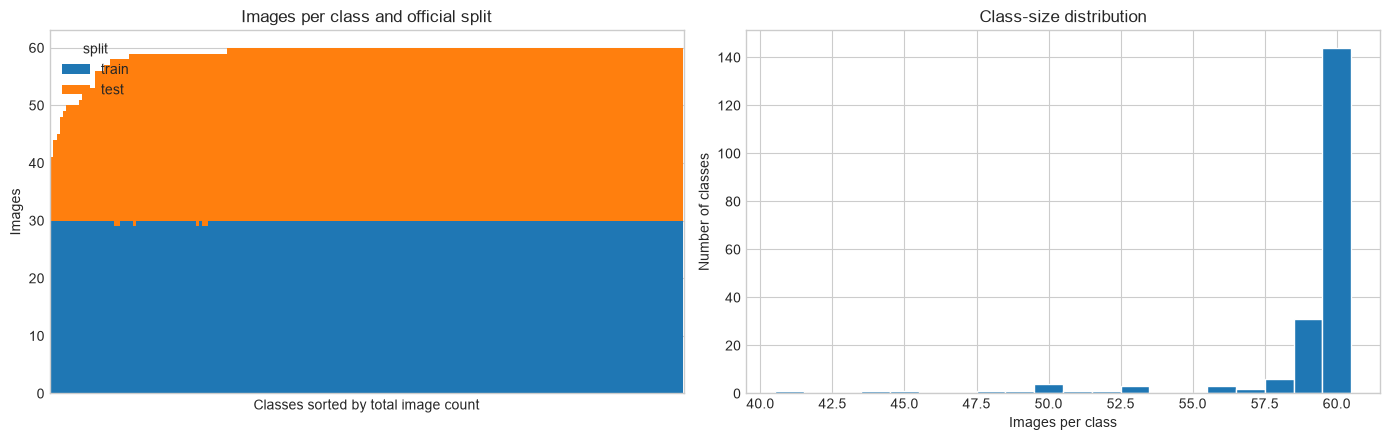

In [32]:
print(json.dumps(summary, indent=2))

class_counts = manifest.groupby(
    ["class_id", "class_name_friendly", "split"], as_index=False
).size().pivot(index=["class_id", "class_name_friendly"], columns="split", values="size").fillna(0)
class_counts["total"] = class_counts.sum(axis=1)
display(class_counts.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
class_counts.sort_values("total")[["train", "test"]].plot(
    kind="bar", stacked=True, ax=axes[0], width=1, legend=True
)
axes[0].set_title("Images per class and official split")
axes[0].set_xlabel("Classes sorted by total image count")
axes[0].set_ylabel("Images")
axes[0].set_xticks([])

axes[1].hist(class_counts["total"], bins=np.arange(class_counts["total"].min() - 0.5, class_counts["total"].max() + 1.5), edgecolor="white")
axes[1].set_title("Class-size distribution")
axes[1].set_xlabel("Images per class")
axes[1].set_ylabel("Number of classes")
plt.tight_layout()
plt.show()


## Resolution, aspect ratio, and orientation

,count,mean,std,min,1%,25%,50%,75%,99%,max
width_px,11788.0,467.886834,63.930494,121.000000,244.000000,495.000000,500.000000,500.000000,500.000000,500.000000
height_px,11788.0,386.029946,70.890307,120.000000,221.000000,333.000000,375.000000,434.000000,500.000000,500.000000
megapixels,11788.0,0.179287,0.031582,0.019460,0.058762,0.166500,0.178500,0.194000,0.250000,0.250000
aspect_ratio,11788.0,1.257480,0.288506,0.375276,0.662000,1.080789,1.333333,1.497006,1.760563,3.597122


split,test,train,All
orientation,,,
landscape,4514,4642,9156
portrait,1160,1214,2374
square,120,138,258
All,5794,5994,11788


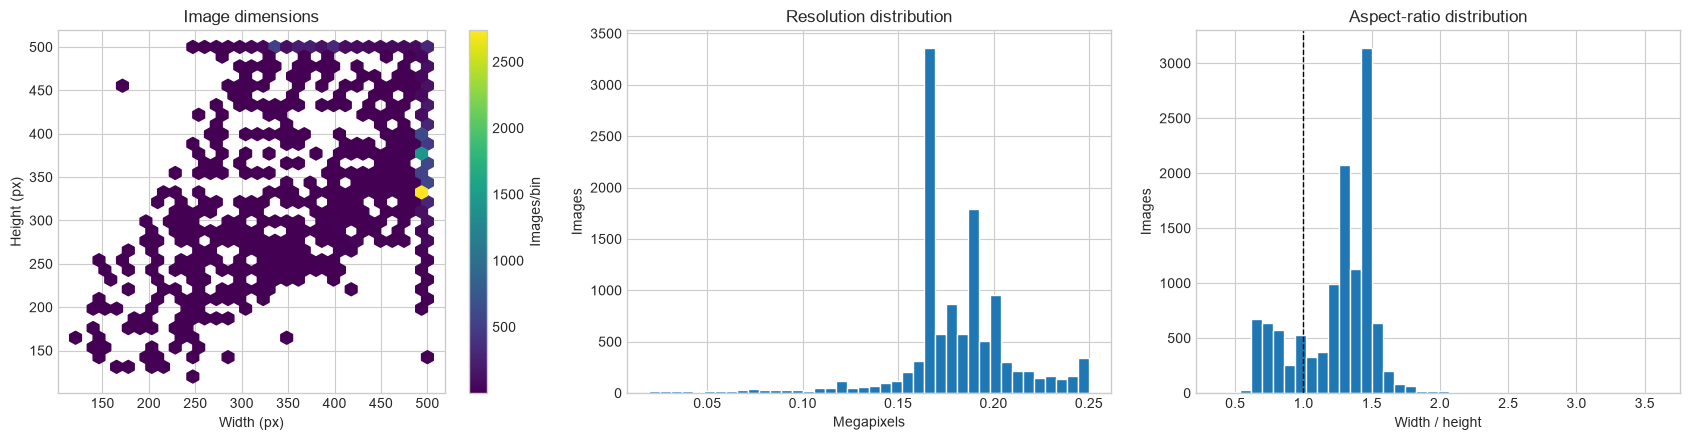

In [34]:
display(manifest[["width_px", "height_px", "megapixels", "aspect_ratio"]].describe(percentiles=[.01, .25, .5, .75, .99]).T)
display(pd.crosstab(manifest["orientation"], manifest["split"], margins=True))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
hexbin = axes[0].hexbin(manifest["width_px"], manifest["height_px"], gridsize=30, mincnt=1, cmap="viridis")
axes[0].set(title="Image dimensions", xlabel="Width (px)", ylabel="Height (px)")
fig.colorbar(hexbin, ax=axes[0], label="Images/bin")
axes[1].hist(manifest["megapixels"], bins=40, edgecolor="white")
axes[1].set(title="Resolution distribution", xlabel="Megapixels", ylabel="Images")
axes[2].hist(manifest["aspect_ratio"], bins=40, edgecolor="white")
axes[2].axvline(1, color="black", linestyle="--", linewidth=1)
axes[2].set(title="Aspect-ratio distribution", xlabel="Width / height", ylabel="Images")
plt.tight_layout()
plt.show()


## JPEG storage and compression proxies

`estimated_compression_ratio = width × height × channel_count / file_bytes`. `encoded_bits_per_pixel = 8 × file_bytes / pixel_count`. These include JPEG headers and cannot recover the original quality/subsampling choices.

,count,mean,std,min,1%,25%,50%,75%,99%,max
file_size_kib,11788.0,95.324241,42.323225,2.559570,12.764600,68.138428,91.673828,118.681885,216.865400,358.228516
estimated_uncompressed_bytes,11788.0,537591.054038,95100.843843,58380.000000,174798.390000,499500.000000,535500.000000,582000.000000,750000.000000,750000.000000
estimated_compression_ratio,11788.0,6.919600,4.827953,1.305970,2.511069,4.541170,5.755934,7.464088,27.694515,85.338645
encoded_bits_per_pixel,11788.0,4.335052,1.775891,0.281232,0.866598,3.210519,4.169066,5.282337,9.505241,18.377143


image_mode,L,RGB,All
image_format,,,
JPEG,8,11780,11788
All,8,11780,11788


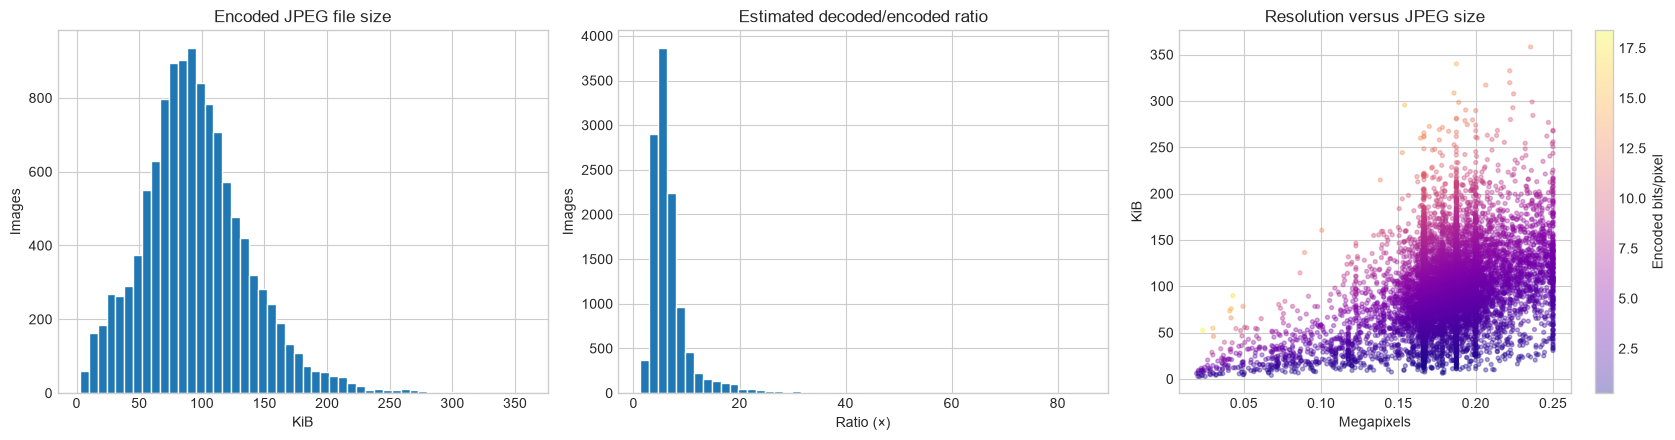

In [36]:
display(manifest[[
    "file_size_kib", "estimated_uncompressed_bytes", "estimated_compression_ratio", "encoded_bits_per_pixel"
]].describe(percentiles=[.01, .25, .5, .75, .99]).T)
display(pd.crosstab(manifest["image_format"], manifest["image_mode"], margins=True))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(manifest["file_size_kib"], bins=50, edgecolor="white")
axes[0].set(title="Encoded JPEG file size", xlabel="KiB", ylabel="Images")
axes[1].hist(manifest["estimated_compression_ratio"], bins=50, edgecolor="white")
axes[1].set(title="Estimated decoded/encoded ratio", xlabel="Ratio (×)", ylabel="Images")
scatter = axes[2].scatter(
    manifest["megapixels"], manifest["file_size_kib"],
    c=manifest["encoded_bits_per_pixel"], s=8, alpha=.35, cmap="plasma"
)
axes[2].set(title="Resolution versus JPEG size", xlabel="Megapixels", ylabel="KiB")
fig.colorbar(scatter, ax=axes[2], label="Encoded bits/pixel")
plt.tight_layout()
plt.show()


## Bounding boxes and parts

,count,mean,std,min,25%,50%,75%,max
bbox_area_fraction,11788.0,0.345891,0.176329,0.050054,0.207491,0.317363,0.454094,1.000000
visible_part_count,11788.0,11.995843,1.319586,3.000000,11.000000,12.000000,13.000000,15.000000
mturk_part_click_count,11788.0,67.378521,3.650334,48.000000,66.000000,68.000000,69.000000,75.000000
mturk_mean_click_time_seconds,11788.0,3.793048,1.081102,2.302456,3.171451,3.519683,4.028430,14.412059


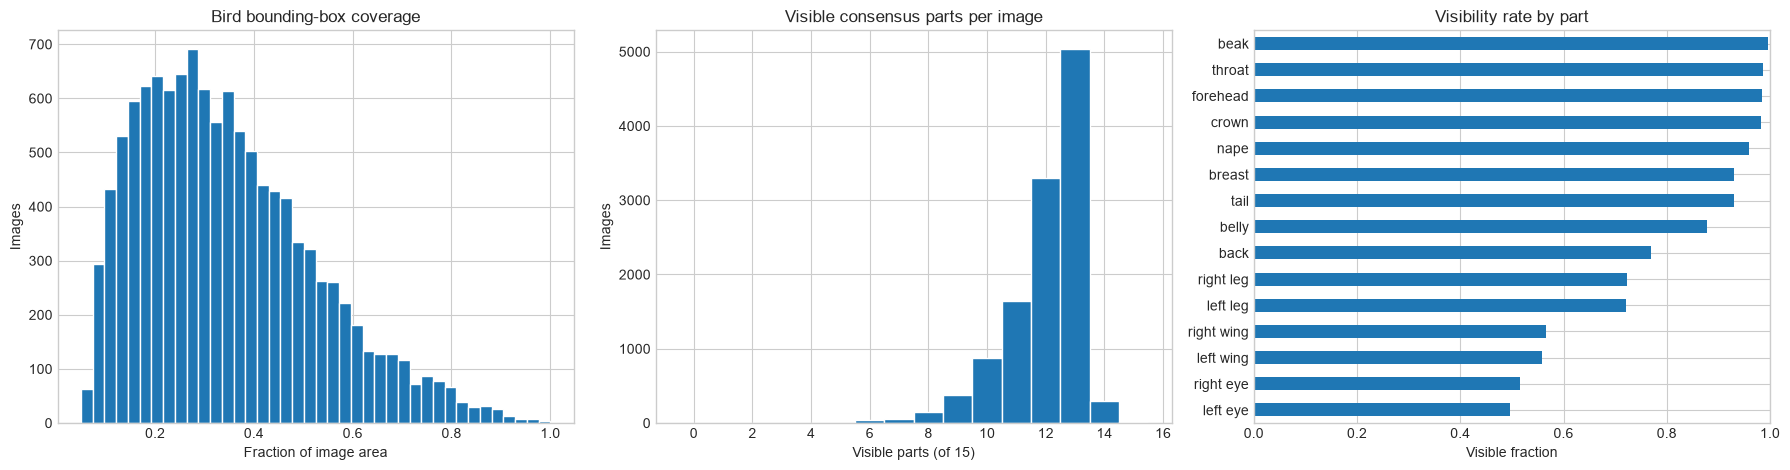

In [12]:
display(manifest[["bbox_area_fraction", "visible_part_count", "mturk_part_click_count", "mturk_mean_click_time_seconds"]].describe().T)

part_visibility = (
    part_locations.groupby("part_name")["part_visible"].mean().sort_values()
)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].hist(manifest["bbox_area_fraction"], bins=40, edgecolor="white")
axes[0].set(title="Bird bounding-box coverage", xlabel="Fraction of image area", ylabel="Images")
axes[1].hist(manifest["visible_part_count"], bins=np.arange(-.5, 16.5, 1), edgecolor="white")
axes[1].set(title="Visible consensus parts per image", xlabel="Visible parts (of 15)", ylabel="Images")
part_visibility.plot(kind="barh", ax=axes[2])
axes[2].set(title="Visibility rate by part", xlabel="Visible fraction", ylabel="")
axes[2].set_xlim(0, 1)
plt.tight_layout()
plt.show()


## Image-level attribute prevalence and certainty

,attribute_id,attribute_name,prevalence,mean_certainty_id
142,143,has_eye_color::green,0.001272,3.551408
271,272,has_leg_color::green,0.001442,3.084662
137,138,has_eye_color::purple,0.001527,3.551408
286,287,has_bill_color::green,0.002375,3.507720
141,142,has_eye_color::olive,0.002545,3.551408
281,282,has_bill_color::purple,0.002799,3.507720
108,109,has_breast_color::purple,0.002969,3.408975
170,171,has_under_tail_color::purple,0.003308,2.813030
82,83,has_upper_tail_color::purple,0.003308,2.603580
200,201,has_belly_color::purple,0.003308,3.321598


,attribute_id,attribute_name,prevalence,mean_certainty_id
145,146,has_eye_color::black,0.837462,3.551408
244,245,has_belly_pattern::solid,0.573465,3.309382
151,152,has_bill_length::shorter_than_head,0.561079,3.511198
54,55,has_breast_pattern::solid,0.548269,3.386580
218,219,has_size::small_(5_-_9_in),0.511537,3.346030
235,236,has_shape::perching-like,0.486766,3.410842
289,290,has_bill_color::black,0.441805,3.507720
20,21,has_wing_color::black,0.428487,3.331439
6,7,has_bill_shape::all-purpose,0.391754,3.463522
35,36,has_upperparts_color::black,0.391245,3.225314


is_present,0,1
certainty_name,,
definitely,0.548,0.599
guessing,0.061,0.074
not visible,0.119,0.000
probably,0.272,0.328


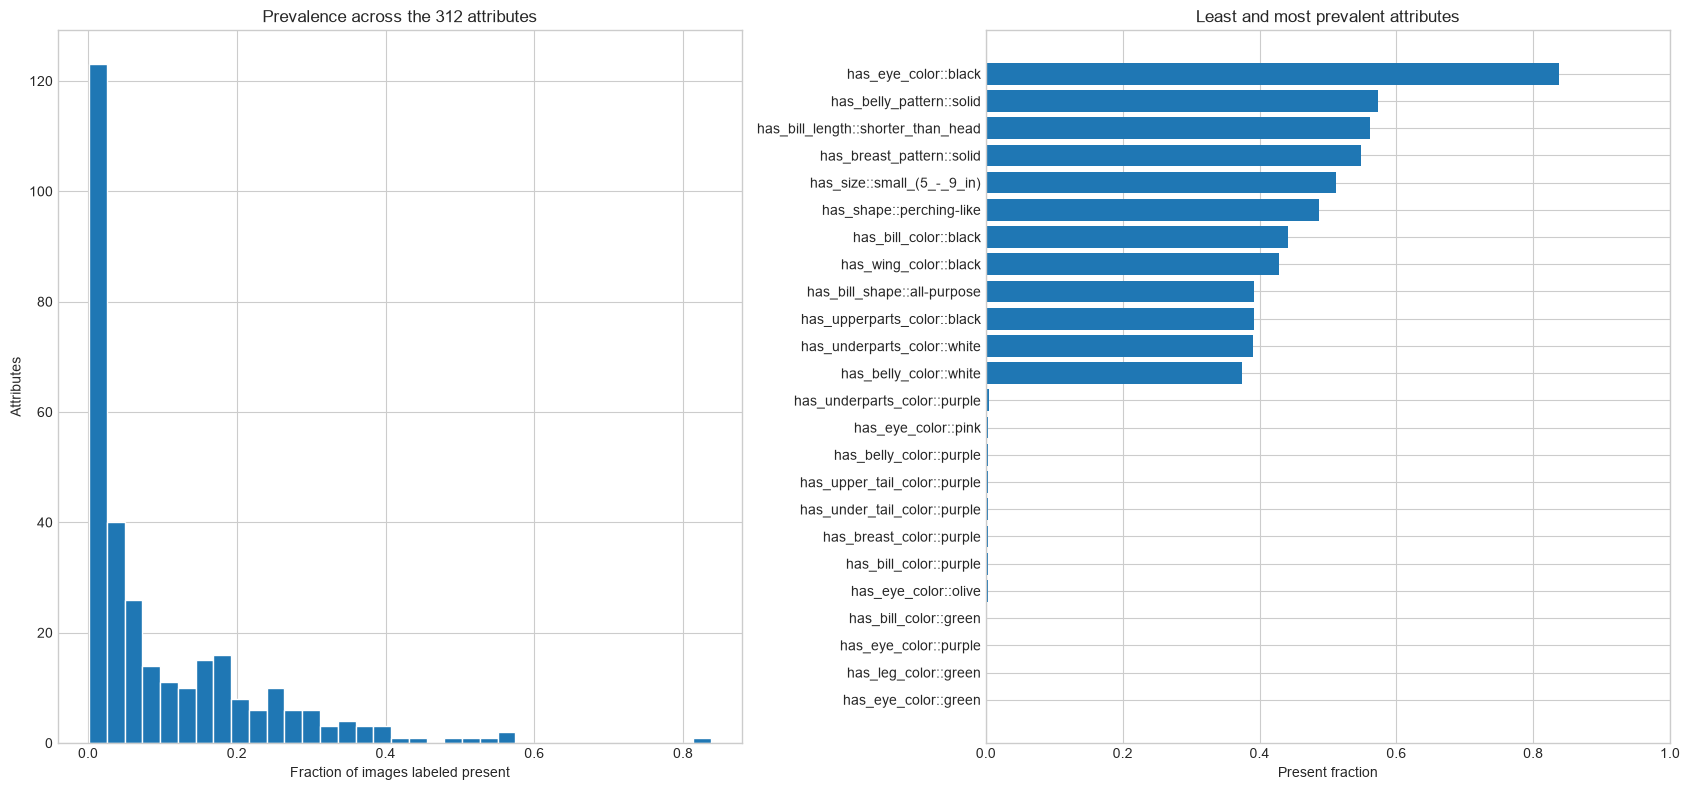

In [38]:
attribute_prevalence = (
    attribute_annotations.groupby(["attribute_id", "attribute_name"], as_index=False)
    .agg(prevalence=("is_present", "mean"), mean_certainty_id=("certainty_id", "mean"))
    .sort_values("prevalence")
)
display(attribute_prevalence.head(10))
display(attribute_prevalence.tail(10).sort_values("prevalence", ascending=False))
display(pd.crosstab(attribute_annotations["certainty_name"], attribute_annotations["is_present"], normalize="columns").round(3))

extremes = pd.concat([attribute_prevalence.head(12), attribute_prevalence.tail(12)]).sort_values("prevalence")
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
axes[0].hist(attribute_prevalence["prevalence"], bins=35, edgecolor="white")
axes[0].set(title="Prevalence across the 312 attributes", xlabel="Fraction of images labeled present", ylabel="Attributes")
axes[1].barh(extremes["attribute_name"], extremes["prevalence"])
axes[1].set(title="Least and most prevalent attributes", xlabel="Present fraction", ylabel="")
axes[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()


## Reproducible sample images with bounding boxes

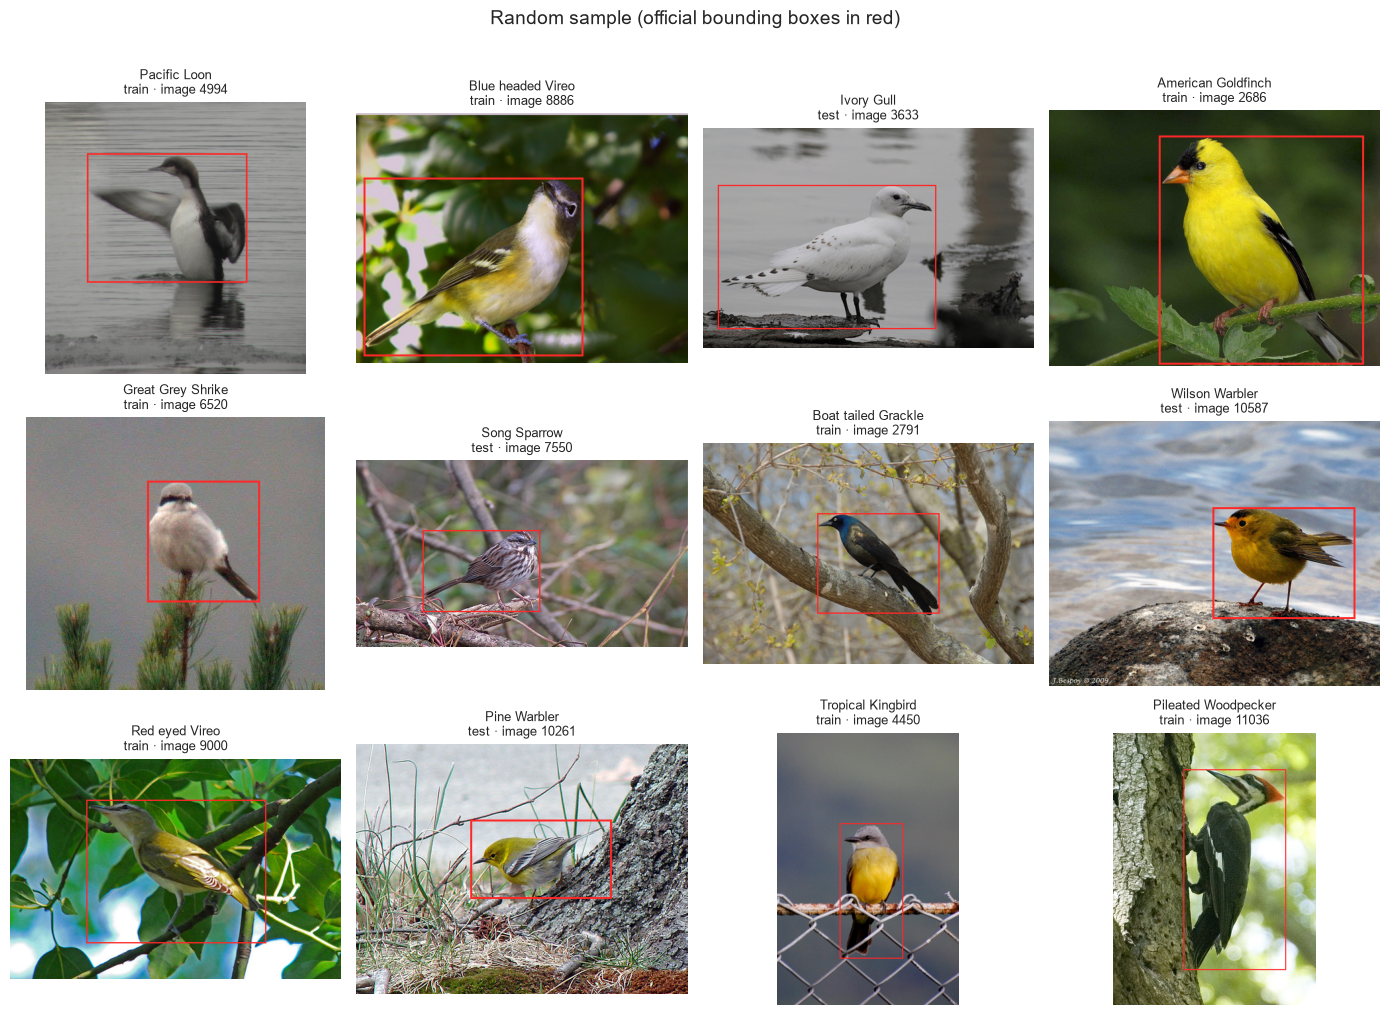

In [40]:
sample = manifest.sample(n=12, random_state=2011)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, row in zip(axes.flat, sample.itertuples(index=False)):
    with Image.open(row.image_path) as image:
        shown = image.convert("RGB")
    draw = ImageDraw.Draw(shown)
    draw.rectangle(
        [row.bbox_x, row.bbox_y, row.bbox_right, row.bbox_bottom],
        outline=(255, 40, 40), width=max(2, round(min(shown.size) / 150)),
    )
    ax.imshow(shown)
    ax.set_title(f"{row.class_name_friendly}\n{row.split} · image {row.image_id}", fontsize=9)
    ax.axis("off")
plt.suptitle("Random sample (official bounding boxes in red)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()
